In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt,
    ExponentialSmoothing
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")

PROJECT_DIR = r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"

FEATURE_DIR = os.path.join(PROJECT_DIR, "data", "features")
REPORT_DIR = os.path.join(PROJECT_DIR, "outputs", "reports")
CHART_DIR = os.path.join(PROJECT_DIR, "outputs", "charts")
FORECAST_DIR = os.path.join(PROJECT_DIR, "data", "forecasts")

for folder in [REPORT_DIR, CHART_DIR, FORECAST_DIR]:
    os.makedirs(folder, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

print("Notebook 06 configuration completed.")

Notebook 06 configuration completed.


In [3]:
def load_price_series(symbol):

    file_path = os.path.join(
        FEATURE_DIR,
        f"{symbol}_features_full.csv"
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(file_path)

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"])
    df = df.sort_values("date")
    df = df.drop_duplicates(subset=["date"], keep="last")

    price_column = (
        "adj_close"
        if "adj_close" in df.columns
        and df["adj_close"].notna().any()
        else "close"
    )

    df[price_column] = pd.to_numeric(
        df[price_column], errors="coerce"
    )

    df = df.dropna(subset=[price_column])
    df = df[df[price_column] > 0]

    series = df.set_index("date")[price_column].astype(float)
    series.name = symbol

    return series


market_series = {}

for symbol in INSTRUMENTS:

    try:
        market_series[symbol] = load_price_series(symbol)
        print(symbol, "loaded:", len(market_series[symbol]))

    except Exception as error:
        print(symbol, "could not be loaded:", error)

print("\nTotal instruments loaded:", len(market_series))

NIFTY50 loaded: 1236
BANKNIFTY loaded: 1235
RELIANCE loaded: 1237
TCS loaded: 1237
HDFCBANK loaded: 1237
INFY loaded: 1237
ICICIBANK loaded: 1237
SBIN loaded: 1237
ITC loaded: 1237
LT loaded: 1237

Total instruments loaded: 10


In [4]:
INITIAL_TRAIN_RATIO = 0.80
FORECAST_HORIZON = 20
N_FOLDS = 6
MIN_TRAIN_SIZE = 300

print("Initial training ratio:", INITIAL_TRAIN_RATIO)
print("Forecast horizon:", FORECAST_HORIZON, "observations")
print("Walk-forward folds:", N_FOLDS)

Initial training ratio: 0.8
Forecast horizon: 20 observations
Walk-forward folds: 6


In [5]:
def generate_walk_forward_folds(series):

    n = len(series)

    first_test_start = int(n * INITIAL_TRAIN_RATIO)
    last_test_start = n - FORECAST_HORIZON

    if first_test_start < MIN_TRAIN_SIZE:
        raise ValueError("Not enough initial training observations.")

    if last_test_start < first_test_start:
        raise ValueError("Not enough observations for the requested folds.")

    fold_starts = np.linspace(
        first_test_start,
        last_test_start,
        N_FOLDS
    )

    fold_starts = np.unique(
        np.round(fold_starts).astype(int)
    )

    folds = []

    for fold_number, start in enumerate(fold_starts, start=1):

        train = series.iloc[:start]

        test = series.iloc[
            start:start + FORECAST_HORIZON
        ]

        if len(train) < MIN_TRAIN_SIZE or len(test) < 5:
            continue

        folds.append({
            "fold": fold_number,
            "train": train,
            "test": test,
            "train_end": train.index[-1],
            "test_start": test.index[0],
            "test_end": test.index[-1]
        })

    return folds


nifty_folds = generate_walk_forward_folds(
    market_series["NIFTY50"]
)

fold_summary = pd.DataFrame([
    {
        "Fold": fold["fold"],
        "Training Observations": len(fold["train"]),
        "Testing Observations": len(fold["test"]),
        "Training Ends": fold["train_end"],
        "Testing Starts": fold["test_start"],
        "Testing Ends": fold["test_end"]
    }
    for fold in nifty_folds
])

display(fold_summary)

,Fold,Training Observations,Testing Observations,Training Ends,Testing Starts,Testing Ends
0,1,988,20,2025-11-19,2025-11-20,2025-12-17
1,2,1034,20,2026-01-27,2026-01-28,2026-02-24
2,3,1079,20,2026-04-06,2026-04-07,2026-05-06
3,4,1125,20,2026-06-12,2026-06-15,2026-07-13
4,5,1170,20,2026-08-17,2026-08-18,2026-09-15
5,6,1216,20,2026-10-23,2026-10-26,2026-11-23


In [6]:
def forecast_naive(train, horizon):
    return np.repeat(train.iloc[-1], horizon)


def forecast_moving_average(train, horizon, window=20):
    average = train.tail(window).mean()
    return np.repeat(average, horizon)


def forecast_ses(train, horizon):

    fitted = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    ).fit(optimized=True)

    return fitted.forecast(horizon)


def forecast_holt(train, horizon):

    fitted = Holt(
        train,
        initialization_method="estimated"
    ).fit(optimized=True)

    return fitted.forecast(horizon)


def forecast_holt_winters(train, horizon):

    fitted = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=5,
        initialization_method="estimated"
    ).fit(optimized=True)

    return fitted.forecast(horizon)


def forecast_arima(train, horizon):

    fitted = ARIMA(
        train,
        order=(1, 1, 1)
    ).fit()

    return fitted.forecast(steps=horizon)


MODEL_FUNCTIONS = {
    "Naive": forecast_naive,
    "Moving Average 20": forecast_moving_average,
    "SES": forecast_ses,
    "Holt Linear": forecast_holt,
    "Holt-Winters": forecast_holt_winters,
    "ARIMA(1,1,1)": forecast_arima
}

print("Models configured:", list(MODEL_FUNCTIONS.keys()))

Models configured: ['Naive', 'Moving Average 20', 'SES', 'Holt Linear', 'Holt-Winters', 'ARIMA(1,1,1)']


In [7]:
def evaluate_forecast(actual, predicted, previous_actual):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    previous_actual = np.asarray(previous_actual, dtype=float)

    valid = (
        np.isfinite(actual)
        & np.isfinite(predicted)
        & np.isfinite(previous_actual)
    )

    actual = actual[valid]
    predicted = predicted[valid]
    previous_actual = previous_actual[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MAPE": np.nan,
            "Directional_Accuracy": np.nan
        }

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    nonzero = actual != 0

    mape = (
        np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
        if nonzero.any()
        else np.nan
    )

    actual_direction = np.sign(actual - previous_actual)
    predicted_direction = np.sign(predicted - previous_actual)

    directional_accuracy = np.mean(
        actual_direction == predicted_direction
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Directional_Accuracy": directional_accuracy
    }

In [8]:
walk_forward_results = []
walk_forward_predictions = []

for symbol, series in market_series.items():

    print(f"\nProcessing {symbol}...")

    try:
        folds = generate_walk_forward_folds(series)

    except Exception as error:
        print("Skipping instrument:", error)
        continue

    for fold in folds:

        train = fold["train"]
        test = fold["test"]
        horizon = len(test)

        previous_actual = np.concatenate([
            [train.iloc[-1]],
            test.iloc[:-1].values
        ])

        for model_name, model_function in MODEL_FUNCTIONS.items():

            try:
                predicted_values = model_function(
                    train,
                    horizon
                )

                predicted_values = np.asarray(
                    predicted_values,
                    dtype=float
                )

                if len(predicted_values) != horizon:
                    raise ValueError("Forecast length mismatch.")

                metrics = evaluate_forecast(
                    test.values,
                    predicted_values,
                    previous_actual
                )

                walk_forward_results.append({
                    "Instrument": symbol,
                    "Fold": fold["fold"],
                    "Model": model_name,
                    "Train_Start": train.index[0],
                    "Train_End": train.index[-1],
                    "Test_Start": test.index[0],
                    "Test_End": test.index[-1],
                    **metrics
                })

                for date, actual_value, forecast_value in zip(
                    test.index,
                    test.values,
                    predicted_values
                ):

                    walk_forward_predictions.append({
                        "Date": date,
                        "Instrument": symbol,
                        "Fold": fold["fold"],
                        "Model": model_name,
                        "Actual": actual_value,
                        "Forecast": forecast_value,
                        "Error": actual_value - forecast_value
                    })

                print(
                    f"  Fold {fold['fold']} | "
                    f"{model_name}: completed"
                )

            except Exception as error:

                print(
                    f"  Fold {fold['fold']} | "
                    f"{model_name}: failed — {error}"
                )


walk_forward_df = pd.DataFrame(walk_forward_results)
walk_forward_predictions_df = pd.DataFrame(
    walk_forward_predictions
)

print("\nWalk-forward validation completed.")
print("Evaluation rows:", len(walk_forward_df))
print("Forecast rows:", len(walk_forward_predictions_df))

display(walk_forward_df.head(10))


Processing NIFTY50...
  Fold 1 | Naive: completed
  Fold 1 | Moving Average 20: completed
  Fold 1 | SES: failed — No supported index is available.
  Fold 1 | Holt Linear: failed — No supported index is available.
  Fold 1 | Holt-Winters: failed — No supported index is available.
  Fold 1 | ARIMA(1,1,1): failed — No supported index is available.
  Fold 2 | Naive: completed
  Fold 2 | Moving Average 20: completed
  Fold 2 | SES: failed — No supported index is available.
  Fold 2 | Holt Linear: failed — No supported index is available.
  Fold 2 | Holt-Winters: failed — No supported index is available.
  Fold 2 | ARIMA(1,1,1): failed — No supported index is available.
  Fold 3 | Naive: completed
  Fold 3 | Moving Average 20: completed
  Fold 3 | SES: failed — No supported index is available.
  Fold 3 | Holt Linear: failed — No supported index is available.
  Fold 3 | Holt-Winters: failed — No supported index is available.
  Fold 3 | ARIMA(1,1,1): failed — No supported index is available.

,Instrument,Fold,Model,Train_Start,Train_End,Test_Start,Test_End,MAE,RMSE,MAPE,Directional_Accuracy
0,NIFTY50,1,Naive,2021-11-23,2025-11-19,2025-11-20,2025-12-17,122.815039,145.640518,0.472715,55.0
1,NIFTY50,1,Moving Average 20,2021-11-23,2025-11-19,2025-11-20,2025-12-17,204.567031,243.589864,0.783572,70.0
2,NIFTY50,2,Naive,2021-11-23,2026-01-27,2026-01-28,2026-02-24,455.104688,498.869289,1.769502,40.0
3,NIFTY50,2,Moving Average 20,2021-11-23,2026-01-27,2026-01-28,2026-02-24,193.829922,256.646706,0.761367,75.0
4,NIFTY50,3,Naive,2021-11-23,2026-04-06,2026-04-07,2026-05-06,1117.157520,1155.247793,4.623823,45.0
5,NIFTY50,3,Moving Average 20,2021-11-23,2026-04-06,2026-04-07,2026-05-06,744.958643,778.594878,3.082403,55.0
6,NIFTY50,4,Naive,2021-11-23,2026-06-12,2026-06-15,2026-07-13,450.634570,481.018812,1.867132,30.0
7,NIFTY50,4,Moving Average 20,2021-11-23,2026-06-12,2026-06-15,2026-07-13,535.320117,561.137425,2.218927,30.0
8,NIFTY50,5,Naive,2021-11-23,2026-08-17,2026-08-18,2026-09-15,371.992871,496.046071,1.574775,35.0
9,NIFTY50,5,Moving Average 20,2021-11-23,2026-08-17,2026-08-18,2026-09-15,406.268896,524.870652,1.718370,35.0


In [9]:
walk_forward_summary = (
    walk_forward_df
    .groupby(["Instrument", "Model"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAPE=("MAPE", "mean"),
        Std_MAPE=("MAPE", "std"),
        Mean_Directional_Accuracy=(
            "Directional_Accuracy", "mean"
        ),
        Std_Directional_Accuracy=(
            "Directional_Accuracy", "std"
        ),
        Successful_Folds=("Fold", "nunique")
    )
    .reset_index()
)

display(
    walk_forward_summary.sort_values(
        ["Instrument", "Mean_RMSE"]
    )
)

,Instrument,Model,Mean_MAE,Std_MAE,Mean_RMSE,Std_RMSE,Mean_MAPE,Std_MAPE,Mean_Directional_Accuracy,Std_Directional_Accuracy,Successful_Folds
1,BANKNIFTY,Naive,1773.789714,1686.198813,2047.225040,2051.607294,3.004232,2.813555,47.500000,9.874209,6
0,BANKNIFTY,Moving Average 20,1993.261868,1432.500955,2261.835888,1710.979341,3.380031,2.386046,48.333333,7.527727,6
3,HDFCBANK,Naive,28.334793,24.928222,33.921342,30.103567,3.512466,3.136620,43.333333,8.164966,6
2,HDFCBANK,Moving Average 20,30.921981,23.480714,34.772673,26.374612,3.879926,2.994242,51.666667,16.931233,6
5,ICICIBANK,Naive,51.120222,41.668944,60.901545,51.234335,3.557815,2.717377,48.333333,6.055301,6
4,ICICIBANK,Moving Average 20,63.081372,59.853030,72.384883,66.717617,4.374058,3.916824,52.500000,19.429359,6
7,INFY,Naive,70.454657,65.116880,84.260958,74.683400,5.729699,4.761575,47.500000,18.907670,6
6,INFY,Moving Average 20,85.733878,43.798233,97.708279,50.739281,7.083752,3.322229,50.000000,12.247449,6
9,ITC,Naive,9.436610,7.026884,10.849109,8.312126,3.211378,2.482198,44.166667,15.942605,6
8,ITC,Moving Average 20,11.483382,6.687213,12.887108,7.375908,3.882130,2.476164,44.166667,11.583034,6


In [10]:
best_walk_forward_models = (
    walk_forward_summary
    .dropna(subset=["Mean_RMSE"])
    .sort_values(
        ["Instrument", "Mean_RMSE"]
    )
    .groupby("Instrument")
    .first()
    .reset_index()
)

display(best_walk_forward_models)

,Instrument,Model,Mean_MAE,Std_MAE,Mean_RMSE,Std_RMSE,Mean_MAPE,Std_MAPE,Mean_Directional_Accuracy,Std_Directional_Accuracy,Successful_Folds
0,BANKNIFTY,Naive,1773.789714,1686.198813,2047.225040,2051.607294,3.004232,2.813555,47.500000,9.874209,6
1,HDFCBANK,Naive,28.334793,24.928222,33.921342,30.103567,3.512466,3.136620,43.333333,8.164966,6
2,ICICIBANK,Naive,51.120222,41.668944,60.901545,51.234335,3.557815,2.717377,48.333333,6.055301,6
3,INFY,Naive,70.454657,65.116880,84.260958,74.683400,5.729699,4.761575,47.500000,18.907670,6
4,ITC,Naive,9.436610,7.026884,10.849109,8.312126,3.211378,2.482198,44.166667,15.942605,6
5,LT,Moving Average 20,201.812059,131.453345,223.161973,135.821119,4.944232,3.258221,50.000000,10.000000,6
6,NIFTY50,Moving Average 20,631.202098,564.486115,729.717233,660.437926,2.558635,2.251991,50.000000,19.493589,6
7,RELIANCE,Moving Average 20,47.444098,36.349444,53.180898,39.979266,3.440610,2.714714,49.166667,13.570802,6
8,SBIN,Naive,47.457921,33.393602,58.174611,42.887759,4.345076,2.827045,43.333333,9.831921,6
9,TCS,Naive,96.005175,87.469569,115.059253,105.417816,3.817669,3.195071,47.500000,6.123724,6


In [11]:
best_walk_forward_models.to_csv(
    os.path.join(
        REPORT_DIR,
        "best_walk_forward_models.csv"
    ),
    index=False
)

print("Best walk-forward models saved.")

Best walk-forward models saved.


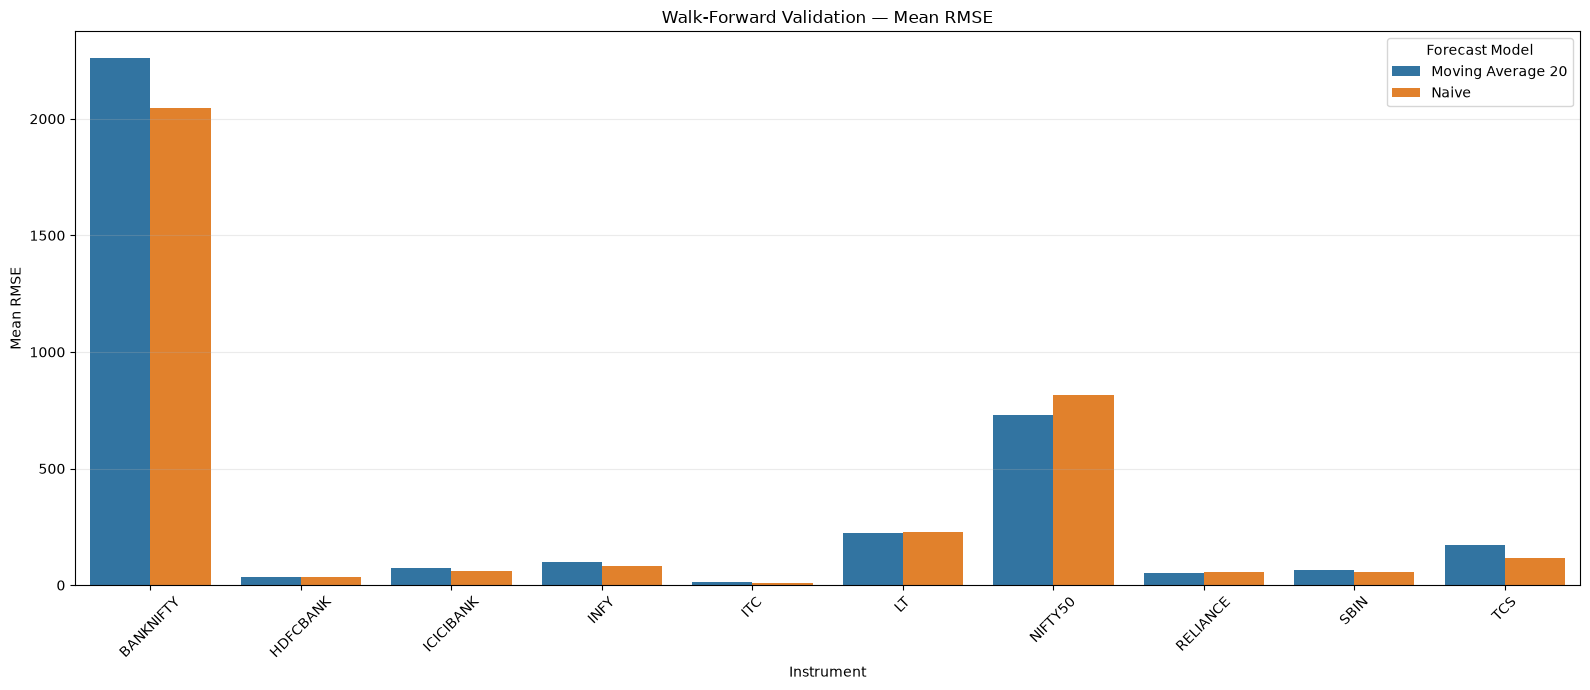

In [12]:
plt.figure(figsize=(16, 7))

sns.barplot(
    data=walk_forward_summary,
    x="Instrument",
    y="Mean_RMSE",
    hue="Model"
)

plt.title("Walk-Forward Validation — Mean RMSE")
plt.xlabel("Instrument")
plt.ylabel("Mean RMSE")
plt.xticks(rotation=45)
plt.legend(title="Forecast Model")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(CHART_DIR, "walk_forward_rmse_comparison.png"),
    dpi=150
)

plt.show()

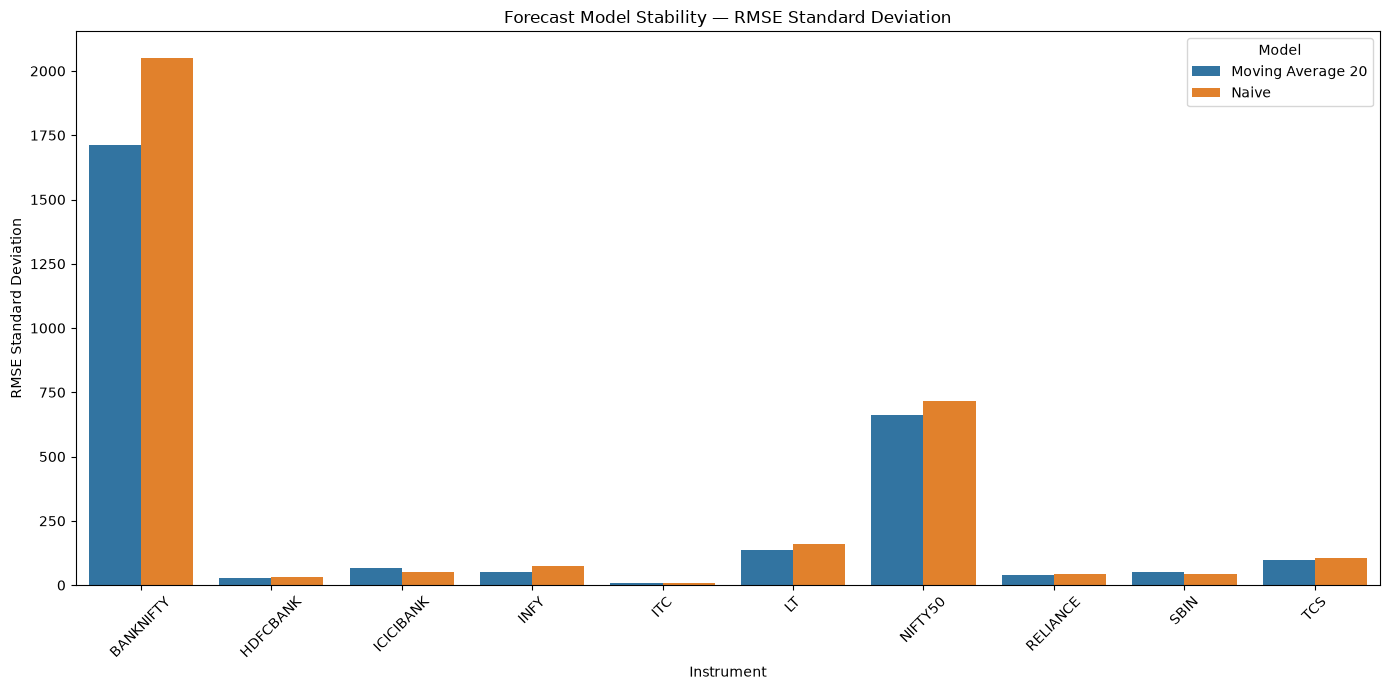

In [13]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=walk_forward_summary,
    x="Instrument",
    y="Std_RMSE",
    hue="Model"
)

plt.title("Forecast Model Stability — RMSE Standard Deviation")
plt.xlabel("Instrument")
plt.ylabel("RMSE Standard Deviation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
nifty_fold_results = walk_forward_df[
    walk_forward_df["Instrument"] == "NIFTY50"
].copy()

display(
    nifty_fold_results[
        [
            "Fold",
            "Model",
            "MAE",
            "RMSE",
            "MAPE",
            "Directional_Accuracy"
        ]
    ].sort_values(["Fold", "RMSE"])
)

,Fold,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,1,Naive,122.815039,145.640518,0.472715,55.0
1,1,Moving Average 20,204.567031,243.589864,0.783572,70.0
3,2,Moving Average 20,193.829922,256.646706,0.761367,75.0
2,2,Naive,455.104688,498.869289,1.769502,40.0
5,3,Moving Average 20,744.958643,778.594878,3.082403,55.0
4,3,Naive,1117.157520,1155.247793,4.623823,45.0
6,4,Naive,450.634570,481.018812,1.867132,30.0
7,4,Moving Average 20,535.320117,561.137425,2.218927,30.0
8,5,Naive,371.992871,496.046071,1.574775,35.0
9,5,Moving Average 20,406.268896,524.870652,1.718370,35.0


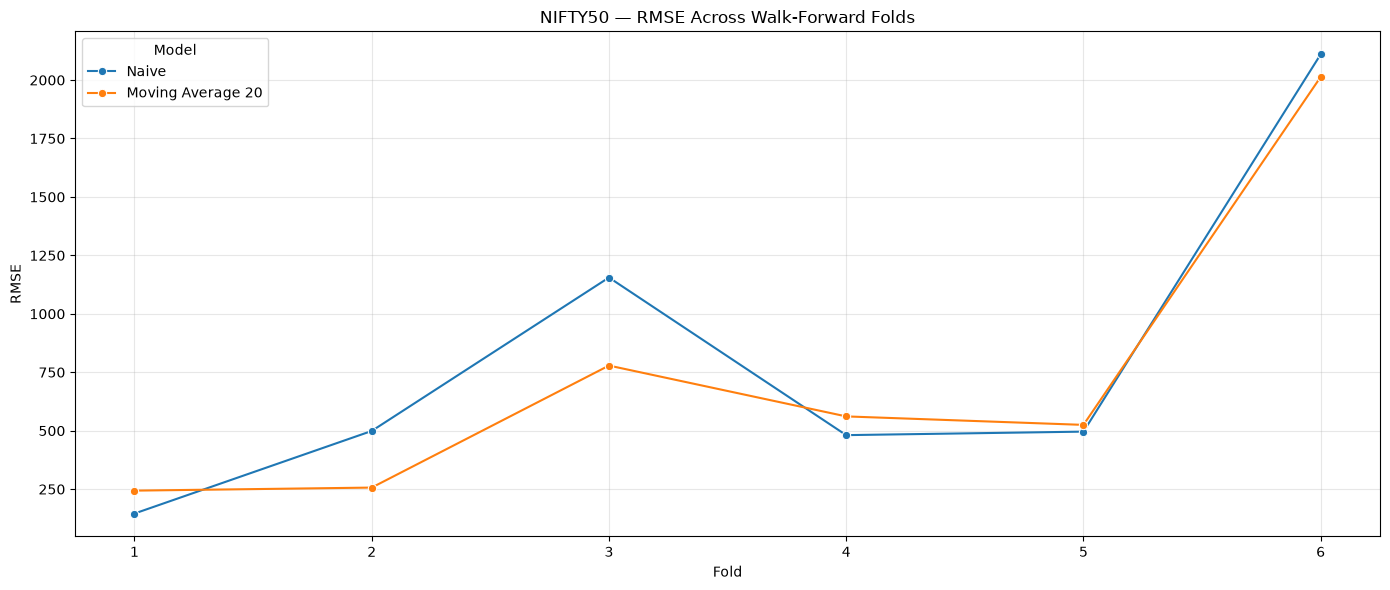

In [15]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=nifty_fold_results,
    x="Fold",
    y="RMSE",
    hue="Model",
    marker="o"
)

plt.title("NIFTY50 — RMSE Across Walk-Forward Folds")
plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

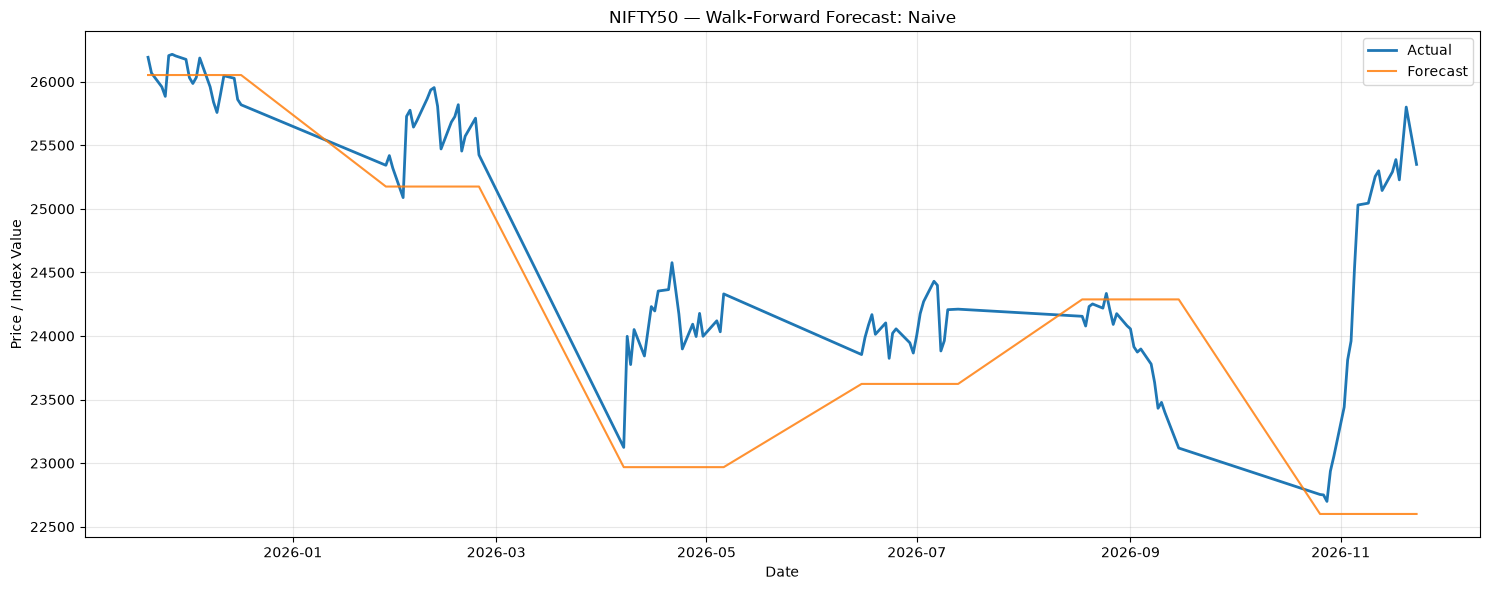

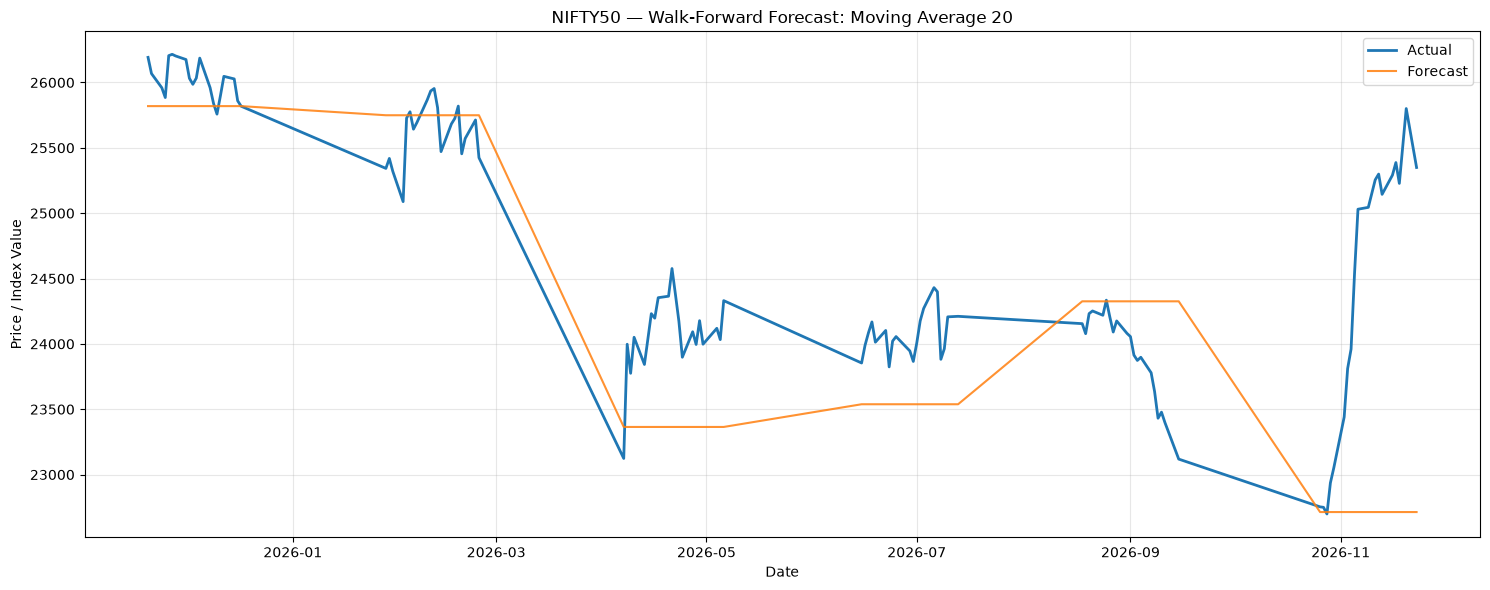

In [16]:
nifty_prediction_data = walk_forward_predictions_df[
    walk_forward_predictions_df["Instrument"] == "NIFTY50"
].copy()

for model_name in MODEL_FUNCTIONS.keys():

    model_data = nifty_prediction_data[
        nifty_prediction_data["Model"] == model_name
    ].sort_values("Date")

    if model_data.empty:
        continue

    plt.figure(figsize=(15, 6))

    plt.plot(
        model_data["Date"],
        model_data["Actual"],
        label="Actual",
        linewidth=2
    )

    plt.plot(
        model_data["Date"],
        model_data["Forecast"],
        label="Forecast",
        alpha=0.85
    )

    plt.title(f"NIFTY50 — Walk-Forward Forecast: {model_name}")
    plt.xlabel("Date")
    plt.ylabel("Price / Index Value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [17]:
residual_diagnostics = []

for symbol in INSTRUMENTS:

    symbol_data = walk_forward_predictions_df[
        walk_forward_predictions_df["Instrument"] == symbol
    ]

    for model_name in MODEL_FUNCTIONS.keys():

        model_data = symbol_data[
            symbol_data["Model"] == model_name
        ].sort_values(["Fold", "Date"])

        residuals = model_data["Error"].dropna()

        if len(residuals) < 30:
            continue

        try:
            result = acorr_ljungbox(
                residuals,
                lags=[10],
                return_df=True
            )

            residual_diagnostics.append({
                "Instrument": symbol,
                "Model": model_name,
                "Observations": len(residuals),
                "Ljung_Box_Lag": 10,
                "Ljung_Box_Statistic": result["lb_stat"].iloc[0],
                "Ljung_Box_P_Value": result["lb_pvalue"].iloc[0]
            })

        except Exception as error:
            print(
                f"Diagnostic failed for {symbol}, "
                f"{model_name}: {error}"
            )


residual_diagnostics_df = pd.DataFrame(
    residual_diagnostics
)

display(residual_diagnostics_df)

,Instrument,Model,Observations,Ljung_Box_Lag,Ljung_Box_Statistic,Ljung_Box_P_Value
0,NIFTY50,Naive,120,10,488.096409,1.541878e-98
1,NIFTY50,Moving Average 20,120,10,468.128052,2.830518e-94
2,BANKNIFTY,Naive,120,10,438.620432,5.581676e-88
3,BANKNIFTY,Moving Average 20,120,10,393.758257,2.004179e-78
4,RELIANCE,Naive,120,10,374.211511,2.873917e-74
5,RELIANCE,Moving Average 20,120,10,405.228335,7.258873e-81
6,TCS,Naive,120,10,285.314437,1.967810e-55
7,TCS,Moving Average 20,120,10,393.621447,2.143107e-78
8,HDFCBANK,Naive,120,10,409.685912,8.162612e-82
9,HDFCBANK,Moving Average 20,120,10,416.521560,2.858199e-83


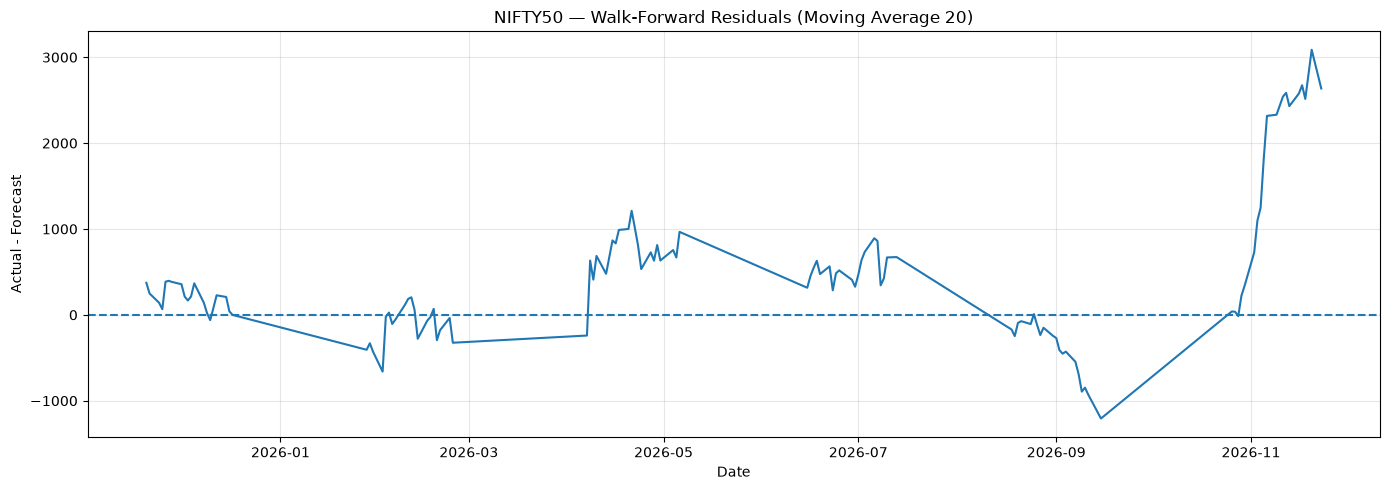

Selected model: Moving Average 20


In [18]:
nifty_best_model = best_walk_forward_models.loc[
    best_walk_forward_models["Instrument"] == "NIFTY50",
    "Model"
].iloc[0]

nifty_residuals = nifty_prediction_data[
    nifty_prediction_data["Model"] == nifty_best_model
].sort_values(["Fold", "Date"])

plt.figure(figsize=(14, 5))

plt.plot(
    nifty_residuals["Date"],
    nifty_residuals["Error"]
)

plt.axhline(0, linestyle="--")

plt.title(
    f"NIFTY50 — Walk-Forward Residuals ({nifty_best_model})"
)

plt.xlabel("Date")
plt.ylabel("Actual - Forecast")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Selected model:", nifty_best_model)

In [19]:
notebook_05_file = os.path.join(
    REPORT_DIR,
    "statistical_forecasting_metrics.csv"
)

if os.path.exists(notebook_05_file):

    notebook_05_metrics = pd.read_csv(notebook_05_file)

    one_shot_comparison = notebook_05_metrics[
        ["Instrument", "Model", "RMSE", "MAE", "MAPE"]
    ].rename(columns={
        "RMSE": "One_Shot_RMSE",
        "MAE": "One_Shot_MAE",
        "MAPE": "One_Shot_MAPE"
    })

    comparison = walk_forward_summary.merge(
        one_shot_comparison,
        on=["Instrument", "Model"],
        how="left"
    )

    display(comparison)

    comparison.to_csv(
        os.path.join(
            REPORT_DIR,
            "one_shot_vs_walk_forward_comparison.csv"
        ),
        index=False
    )

else:
    print(
        "Notebook 05 metrics file not found. "
        "Run Notebook 05 to enable this comparison."
    )

,Instrument,Model,Mean_MAE,Std_MAE,Mean_RMSE,Std_RMSE,Mean_MAPE,Std_MAPE,Mean_Directional_Accuracy,Std_Directional_Accuracy,Successful_Folds,One_Shot_RMSE,One_Shot_MAE,One_Shot_MAPE
0,BANKNIFTY,Moving Average 20,1993.261868,1432.500955,2261.835888,1710.979341,3.380031,2.386046,48.333333,7.527727,6,2650.957416,2152.071266,3.834403
1,BANKNIFTY,Naive,1773.789714,1686.198813,2047.225040,2051.607294,3.004232,2.813555,47.500000,9.874209,6,3219.899437,2583.721597,4.645027
2,HDFCBANK,Moving Average 20,30.921981,23.480714,34.772673,26.374612,3.879926,2.994242,51.666667,16.931233,6,192.962991,170.288945,22.537887
3,HDFCBANK,Naive,28.334793,24.928222,33.921342,30.103567,3.512466,3.136620,43.333333,8.164966,6,205.790608,183.864183,24.259168
4,ICICIBANK,Moving Average 20,63.081372,59.853030,72.384883,66.717617,4.374058,3.916824,52.500000,19.429359,6,80.998852,60.118663,4.390726
5,ICICIBANK,Naive,51.120222,41.668944,60.901545,51.234335,3.557815,2.717377,48.333333,6.055301,6,81.071113,59.738486,4.427824
6,INFY,Moving Average 20,85.733878,43.798233,97.708279,50.739281,7.083752,3.322229,50.000000,12.247449,6,291.471253,265.625921,23.609636
7,INFY,Naive,70.454657,65.116880,84.260958,74.683400,5.729699,4.761575,47.500000,18.907670,6,314.621684,282.838615,25.292413
8,ITC,Moving Average 20,11.483382,6.687213,12.887108,7.375908,3.882130,2.476164,44.166667,11.583034,6,99.023896,92.711726,32.542230
9,ITC,Naive,9.436610,7.026884,10.849109,8.312126,3.211378,2.482198,44.166667,15.942605,6,94.016817,87.385448,30.737768


In [20]:
walk_forward_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "walk_forward_fold_results.csv"
    ),
    index=False
)

walk_forward_summary.to_csv(
    os.path.join(
        REPORT_DIR,
        "walk_forward_model_summary.csv"
    ),
    index=False
)

walk_forward_predictions_df.to_csv(
    os.path.join(
        FORECAST_DIR,
        "walk_forward_predictions.csv"
    ),
    index=False
)

residual_diagnostics_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "walk_forward_residual_diagnostics.csv"
    ),
    index=False
)

print("All walk-forward evaluation files exported.")

All walk-forward evaluation files exported.


In [21]:
summary = {
    "Project": "BharatMarket AI",
    "Notebook": "06 - Forecast Evaluation and Walk-Forward Validation",
    "Instruments Loaded": len(market_series),
    "Instruments Evaluated": walk_forward_df["Instrument"].nunique(),
    "Models Tested": walk_forward_df["Model"].nunique(),
    "Forecast Horizon": FORECAST_HORIZON,
    "Walk-Forward Folds": N_FOLDS,
    "Initial Training Ratio": INITIAL_TRAIN_RATIO,
    "Evaluation Metrics": "MAE, RMSE, MAPE, Directional Accuracy",
    "Validation Method": "Expanding Training Window",
    "Residual Test": "Ljung-Box",
    "Best Models File": "best_walk_forward_models.csv"
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "notebook_06_summary.csv"
    ),
    index=False
)

print("\nNOTEBOOK 06 COMPLETED SUCCESSFULLY")

,Item,Value
0,Project,BharatMarket AI
1,Notebook,06 - Forecast Evaluation and Walk-Forward Vali...
2,Instruments Loaded,10
3,Instruments Evaluated,10
4,Models Tested,2
5,Forecast Horizon,20
6,Walk-Forward Folds,6
7,Initial Training Ratio,0.8
8,Evaluation Metrics,"MAE, RMSE, MAPE, Directional Accuracy"
9,Validation Method,Expanding Training Window



NOTEBOOK 06 COMPLETED SUCCESSFULLY
